# 00. Математический язык и соглашения

Курс «От интерференции до измерения поверхности». [Маршрут](README.md).

**Цели:** восстановить смысл комплексного числа, производной, скалярного произведения и МНК; не путать фазу, OPD и высоту.

Работайте сверху вниз, затем меняйте параметры и выполняйте **Restart Kernel → Run All**.
Все численные примеры учебные: они объясняют метод, а не подтверждают точность прибора.
Рекомендуемый темп: одна тетрадь за занятие, с собственными записями и упражнениями.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage, signal, interpolate, optimize

course_dir = next(p for p in [Path.cwd(), Path.cwd()/"notes"/"interferometry-course"]
                  if (p/"course_lib.py").exists())
if str(course_dir) not in sys.path:
    sys.path.insert(0, str(course_dir))
import course_lib as cl
np.set_printoptions(precision=5, suppress=True)

## 1. Одна задача — несколько разных величин

Камера записывает **интенсивность** $I$, но нас интересует высота $h$.
Между ними лежит цепочка:

$$h \longrightarrow W=\mathrm{OPD}\longrightarrow\varphi=\frac{2\pi W}{\lambda}
\longrightarrow I=a+b\cos\varphi.$$

Здесь $W,h,\lambda$ — длины; $\varphi$ — радианы; $N=\varphi/(2\pi)$ — число периодов.
При нормальном отражении $W=2h$. Поэтому одна и та же **фаза в один период**
означает $W=\lambda$, но $h=\lambda/2$. Это не два разных способа нормировки числа;
это две физически разные величины.

В курсе синтетические X направлены вправо, Y вверх; графики массивов имеют
`origin='lower'`. В Qt строка растёт вниз. Переворот Y меняет знак членов,
нечётных по Y, например наклона Y. Координаты и единицы надо записывать до вычислений.

In [2]:
wavelength_nm = 10600.0  # ИК-стенд проекта; все длины здесь в nm
height_nm = 100.0
opd_nm = 2*height_nm
phase_rad = 2*np.pi*opd_nm/wavelength_nm
print(f"h={height_nm:g} nm; OPD={opd_nm:g} nm; φ={phase_rad:.6f} rad; N={phase_rad/(2*np.pi):.6f}")
assert np.isclose(phase_rad*wavelength_nm/(4*np.pi), height_nm)

h=100 nm; OPD=200 nm; φ=0.118551 rad; N=0.018868


## 2. Комплексное число как вращающийся вектор

Из $i^2=-1$ и формулы Эйлера $e^{i\theta}=\cos\theta+i\sin\theta$ получаем
$z=Ae^{i\theta}$: длина вектора равна $A$, угол — $\theta$.
Умножение на $e^{i\delta}$ поворачивает вектор на $\delta$, а сопряжение
$z^*=Ae^{-i\theta}$ меняет направление угла.

`atan2(Im z, Re z)` учитывает квадрант; `arctan(Im/Re)` теряет его.
Аргумент комплексного числа возвращается только по модулю $2\pi$.
Поэтому комплексное представление удобно, но само по себе не решает развёртку.

atan2: [ 0.3  2.5 -2.5]
Обычный arctan: [ 0.3     -0.64159  0.64159]


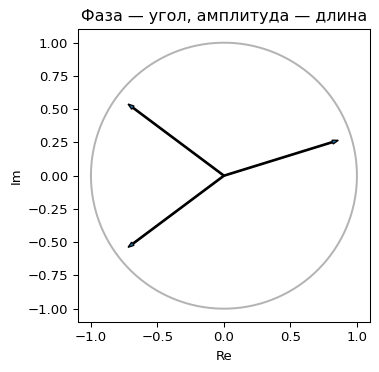

In [3]:
theta = np.array([.3, 2.5, -2.5])
z = np.exp(1j*theta)
print("atan2:", np.angle(z))
print("Обычный arctan:", np.arctan(z.imag/z.real))
t = np.linspace(-np.pi, np.pi, 400)
fig, ax = plt.subplots(figsize=(4,4))
ax.plot(np.cos(t), np.sin(t), color='0.7')
for angle in theta:
    ax.arrow(0,0,.9*np.cos(angle),.9*np.sin(angle),width=.01,length_includes_head=True)
ax.set(aspect='equal', xlabel='Re', ylabel='Im', title='Фаза — угол, амплитуда — длина')
plt.show()

## 3. Производная и градиент: локальная частота полос

Если $\varphi(x)=kx$, один период фазы занимает $T=2\pi/|k|$ единиц X.
Для нелинейной фазы это локальное приближение:

$$\varphi(x+\Delta x)\approx\varphi(x)+\varphi'(x)\Delta x.$$

В двумерном случае $\nabla\varphi=(\partial_x\varphi,\partial_y\varphi)$ направлен
поперёк линий постоянной фазы. Касательный вектор $\mathbf t$ удовлетворяет
$\nabla\varphi\cdot\mathbf t=0$. Отсюда возникает математика трассировки полос.
Производная интенсивности обращается в ноль и на максимумах, и на минимумах:
$\nabla I=-b\sin\varphi\,\nabla\varphi$, если a,b постоянны.
Это объясняет, почему один градиент прямо в центре полосы недостаточен.

Ошибка производной внутри интервала: 3.517186542012496e-13


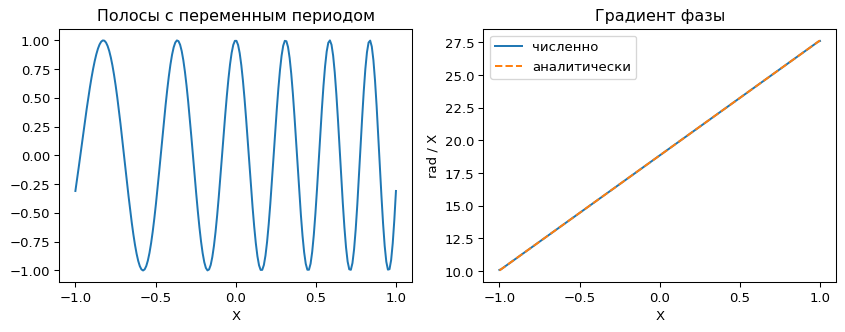

In [4]:
x = np.linspace(-1,1,200)
phi = 2*np.pi*(3*x+.7*x*x)
derivative = np.gradient(phi,x)
exact = 2*np.pi*(3+1.4*x)
print("Ошибка производной внутри интервала:",np.max(np.abs(derivative[1:-1]-exact[1:-1])))
fig, axes = plt.subplots(1,2)
axes[0].plot(x,np.cos(phi)); axes[0].set(title='Полосы с переменным периодом',xlabel='X')
axes[1].plot(x,derivative,label='численно'); axes[1].plot(x,exact,'--',label='аналитически')
axes[1].set(title='Градиент фазы',xlabel='X',ylabel='rad / X'); axes[1].legend()
plt.tight_layout(); plt.show()

## 4. Векторы, проекции и метод наименьших квадратов

Запишем набор измерений вектором $\mathbf y$. Модель — линейная комбинация
известных столбцов: $\mathbf y\approx A\mathbf c$. Столбцы могут быть
$1,x,x^2$ либо $1,\cos\delta,-\sin\delta$.

Ищем минимум $J=\|A\mathbf c-\mathbf y\|^2$. Производная по c даёт
$\nabla_cJ=2A^T(Ac-y)=0$, то есть нормальные уравнения $A^TAc=A^Ty$.
Геометрически остаток перпендикулярен всем столбцам A.

**Вывод уравнений не означает, что надо явно обращать $A^TA$.**
Численно предпочтительны QR или SVD: число обусловленности нормальной матрицы
при полном ранге равно $\kappa(A)^2$. Ранг — количество независимых столбцов;
при его нехватке некоторые параметры невозможно разделить даже без шума.

Истинные / найденные коэффициенты:

 [ 2.  -0.5  0.3] [ 1.99565 -0.50297  0.30228]
Ранг: 3 κ(A): 3.622746029569351 Aᵀr: [ 0. -0.  0.]


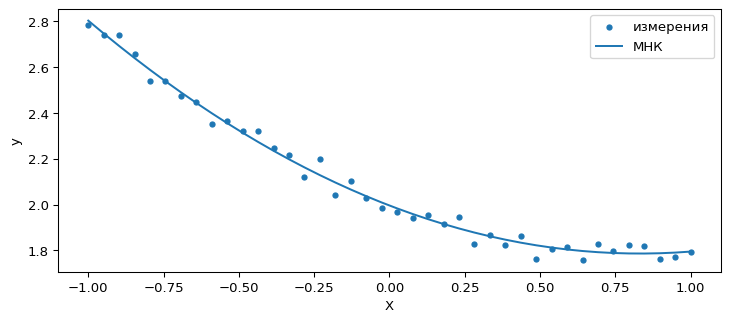

In [5]:
rng = np.random.default_rng(4)
x = np.linspace(-1,1,40)
A = np.column_stack([np.ones_like(x),x,x*x])
truth_c = np.array([2.,-.5,.3])
y = A@truth_c+rng.normal(0,.03,len(x))
c,_,rank,s = np.linalg.lstsq(A,y,rcond=None)
r = y-A@c
print("Истинные / найденные коэффициенты:",truth_c,c)
print("Ранг:",rank,"κ(A):",s[0]/s[-1],"Aᵀr:",A.T@r)
assert np.linalg.norm(A.T@r)<1e-10
fig,ax=plt.subplots(); ax.scatter(x,y,s=14,label='измерения'); ax.plot(x,A@c,label='МНК')
ax.legend(); ax.set(xlabel='X',ylabel='y'); plt.show()

## 5. Ошибка модели и ошибка измерения

Малый остаток МНК доказывает согласие с выбранной моделью, а не правильность
этой модели. Если прибор умножает фазу на 2, достаточно гибкие полиномы всё равно
подгонятся с малым остатком. Поэтому в курсе всегда сохраняется независимая
синтетическая «правда», а ошибка восстановления отделяется от остатка подгонки.

RMS ошибки $\sqrt{\langle(\hat f-f)^2\rangle}$ отличается от СКО поверхности
$\sqrt{\langle(f-\bar f)^2\rangle}$. Удаление пистона, наклона и дефокуса —
разные операции. Нельзя удалять наклон из ошибки только потому, что он оказался неверным.

## Задания

1. Выведите h из φ для отражения; вычислите высоту для φ=π при λ=10.6 μm.
2. Сделайте два одинаковых столбца A. Как изменятся ранг и однозначность коэффициентов?
3. Прибавьте 10 ко всем y. Как изменятся коэффициенты и RMS остатка?

<details><summary>Разбор после собственной попытки</summary>

1. $h=\lambda\varphi/(4\pi)=2.65\,\mu m$. 2. Ранг уменьшается: сумма двух
коэффициентов определена, каждый отдельно — нет. 3. Меняется свободный член на 10;
остаток неизменен, если столбец единиц присутствует.
</details>

**Связь с проектом:** `PhaseMap` используется для разных величин. Учитесь каждый раз
восстанавливать единицы из места её создания, а не из имени класса.
Далее: [волны и интерференция](01_interference.ipynb).